# GVH–CHH | Mercure : contrôle classique vs relativité générale à l’ordre 1PN
**Statut :** contrôle indépendant des modèles H0, non une prédiction originale CHH ou GVH.  
**Protocole figé :** `GVH_CHH_PROTOCOL_FROZEN_v1.0` — **CHH = composition hiérarchique sans dérivée globale intrinsèque**.

- `CHH-STRUCTURE` : la composition CHH n'exige aucune dérivée globale.
- `AUX-DERIVATIVE` : les dérivées numériques/orbitales sont choisies comme auxiliaires, avec hypothèses et unités explicites.
- `KNOWN-PHYSICS` : équation de Kepler et approximation 1PN de la relativité générale.
- `NUMERICAL-TEST` : reproduction de la précession du périhélie dans le problème test Soleil–Mercure.
- `EOM-GVH` : **absent** ; aucune équation de mouvement de l'action GVH n'est testée ici.
- `EMPIRICAL-TEST` : **absent** ; aucune mesure brute indépendante n'est confrontée au modèle.

**Quatre niveaux obligatoires :** ① CHH / GVH (statut) → ② physique établie → ③ test numérique → ④ verdict et limites.

## Niveau 1 — Protocole CHH, hypothèses et préenregistrement

Question de contrôle : un intégrateur orbital isolé reproduit-il (a) zéro précession pour Kepler et (b) la précession relativiste de Mercure prédite analytiquement par la GR à l'ordre 1PN ?

**Hypothèses :** problème plan à deux corps dans la limite masse test ; Soleil ponctuel, sphérique, statique ; pas de perturbations planétaires, pas de quadrupôle solaire, pas de spin, pas de perte d'énergie, pas d'observations de suivi. Les éléments \(a,e\) sont des **entrées approximatives choisies** et non une inférence depuis des données JPL. Les coordonnées sont de type harmonique pour la représentation dynamique 1PN. La trajectoire 1PN n'est fiable qu'au premier ordre en \(c^{-2}\).

**Critères fixés avant calcul :** au moins 45 périhélies détectés en 12 années juliennes ; dérive Kepler < 0,05″/siècle ; erreur relative du signal 1PN–Kepler par rapport à la formule analytique < 0,5 % ; stabilité entre pas maxima 1 jour et 0,5 jour < 0,05″/siècle ; traces numériques non nulles et finies. Un échec de critère doit rester visible, sans recalibration rétrospective.

## Niveau 2 — Physique établie : équations et références

Paramètre gravitationnel solaire \(\mu=GM_\odot\) ; demi-grand axe \(a\) ; excentricité \(e\) ; vitesse lumière \(c\).

**Newton–Kepler :**
\[ \ddot{\mathbf r}_N = -\mu\frac{\mathbf r}{r^3}. \]

**Accélération test à 1PN (coordonnées harmoniques, masse centrale statique) :**
\[ \ddot{\mathbf r}_{1PN} = -\mu\frac{\mathbf r}{r^3} + \frac{\mu}{c^2 r^3}\left[\left(\frac{4\mu}{r}-v^2\right)\mathbf r +4(\mathbf r\cdot\mathbf v)\mathbf v\right]. \]

**Précession séculaire analytique attendue :**
\[ \Delta\varpi_{1PN} = \frac{6\pi\mu}{c^2 a(1-e^2)}\quad\text{(radians / orbite)}, \quad P=2\pi\sqrt{a^3/\mu}.\]

**Calculs :** positions en km ; vitesses en km/s ; temps en s ; angles en rad convertis en secondes d'arc par siècle julien (365,25 jours/an). \(d\mathbf r/dt=\mathbf v\) et \(d\mathbf v/dt=\mathbf a\) sont des **calculs auxiliaires issus de KNOWN-PHYSICS** et non des dérivées constitutives de CHH.

Références : [David Tong, GR lectures](https://www.damtp.cam.ac.uk/user/tong/gr/grhtml/S1.html) ; [Oregon State, Mercury](https://sites.science.oregonstate.edu/coursewikis/GGR/book/content/mercury) ; [NASA/JPL, Astrodynamic Parameters](https://ssd.jpl.nasa.gov/astro_par.html) ; [NASA/JPL DE440/441](https://ssd.jpl.nasa.gov/doc/Park.2021.AJ.DE440.pdf).

In [1]:
import json, hashlib, csv, zipfile, math, sys
from pathlib import Path
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from datetime import datetime, timezone

# Paramètres CHOISIS AVANT le calcul : données nominales/approximatives, pas d'ajustement JPL
MU_SUN = 132712440041.279419   # km^3/s^2, paramètre solaire DE440
C_KM_S = 299792.458             # km/s, exact
AU_KM = 149597870.7             # km, définition IAU 2012
A_KM = 0.38709893 * AU_KM        # km, paramètre orbital de référence approximatif
ECC = 0.20563069                # excentricité de référence approximative
YEAR_DAYS = 365.25              # année julienne
DURATION_YEARS = 12.0
MAX_STEP_DAYS = [1.0, 0.5]
REL_TOL = 2e-12
ABS_TOL = [1e-5, 1e-5, 1e-12, 1e-12] # km,km,km/s,km/s
OUT = Path('/content/GVH_CHH_MERCURY_1PN_CONTROL') if Path('/content').is_dir() else Path('/mnt/data/GVH_CHH_MERCURY_1PN_CONTROL')
OUT.mkdir(parents=True, exist_ok=True)

PROTOCOL = 'GVH_CHH_PROTOCOL_FROZEN_v1.0'
PERIOD_SEC = 2*np.pi*np.sqrt(A_KM**3/MU_SUN)
RAD_TO_ARCSEC = 180/np.pi * 3600
ARCSEC_CENTURY = RAD_TO_ARCSEC * 100 * YEAR_DAYS * 86400
print('Frozen protocol:', PROTOCOL)
print('Mercury nominal period (days):', PERIOD_SEC/86400)
print('Outputs:',OUT)


Frozen protocol: GVH_CHH_PROTOCOL_FROZEN_v1.0
Mercury nominal period (days): 87.96935003249773
Outputs: /content/GVH_CHH_MERCURY_1PN_CONTROL


In [2]:
# Prévision analytique 1PN (sans calibrer sur la solution numérique)
delta_per_orbit_rad = 6*np.pi*MU_SUN/(C_KM_S**2*A_KM*(1-ECC**2))
predicted_arcsec_century = delta_per_orbit_rad * (100*YEAR_DAYS*86400/PERIOD_SEC) * RAD_TO_ARCSEC
print('GR 1PN analytic prediction (arcsec / Julian century): %.9f' % predicted_arcsec_century)
assert 42.0 < predicted_arcsec_century < 44.0


GR 1PN analytic prediction (arcsec / Julian century): 42.980473073


In [3]:
# État initial légèrement APRÈS le périhélie pour éviter un événement t=0 ambigu.
F0_RAD = 0.16
P_SEMILATUS = A_KM*(1-ECC*ECC)
r_initial = P_SEMILATUS/(1+ECC*np.cos(F0_RAD))
v_circ_factor = np.sqrt(MU_SUN/P_SEMILATUS)
Y0 = np.array([r_initial*np.cos(F0_RAD), r_initial*np.sin(F0_RAD),
               -v_circ_factor*np.sin(F0_RAD), v_circ_factor*(ECC+np.cos(F0_RAD))], dtype=float)

def accel(y, one_pn):
    pos=y[:2]; vel=y[2:]
    norm=np.linalg.norm(pos)
    newton=-MU_SUN*pos/norm**3
    if not one_pn: return newton
    v2=np.dot(vel,vel); rv=np.dot(pos,vel)
    return newton + MU_SUN/(C_KM_S**2*norm**3) * ((4*MU_SUN/norm-v2)*pos+4*rv*vel)

def rhs(one_pn):
    def fn(t,y): return np.r_[y[2:],accel(y,one_pn)]
    return fn

def peri_event(t,y):
    return np.dot(y[:2],y[2:]) / np.linalg.norm(y[:2]) # radial speed crosses negative → positive
peri_event.direction=1
peri_event.terminal=False

def integrate(one_pn, max_step_days):
    result=solve_ivp(rhs(one_pn), (0,DURATION_YEARS*YEAR_DAYS*86400), Y0,
                     method='DOP853', rtol=REL_TOL,atol=ABS_TOL,
                     events=peri_event, max_step=max_step_days*86400)
    if not result.success: raise RuntimeError(result.message)
    ev=result.y_events[0]; ts=result.t_events[0]
    if len(ev)<3: raise RuntimeError('Too few perihelion events.')
    angles=np.unwrap(np.arctan2(ev[:,1],ev[:,0]))
    x=ts-ts[0]; y=angles-angles[0]
    slope=np.polyfit(x,y,deg=1)[0]
    return dict(one_pn=bool(one_pn),max_step_days=max_step_days,n_events=len(ev),nfev=result.nfev,
                slope_arcsec_century=float(slope*ARCSEC_CENTURY),
                epochs_s=ts.tolist(),perihelion_angles_rad=angles.tolist(),
                fit_residual_std_arcsec=float(np.std((y-slope*x)*RAD_TO_ARCSEC)))

# Tests mathématiques locaux, sans résultat scientifique nouveau
r=np.array([A_KM,0.0]); v=np.array([0.0,np.sqrt(MU_SUN/A_KM)])
assert np.allclose(accel(np.r_[r,v],False),np.array([-MU_SUN/A_KM**2,0.0]),rtol=1e-13)
assert np.isfinite(accel(np.r_[r,v],True)).all()
print('PASS physical-unit and force smoke checks')


PASS physical-unit and force smoke checks


## Niveau 3 — Test numérique et robustesse aux pas temporels

On intègre deux systèmes avec **exactement les mêmes conditions initiales**, sans ajustement de paramètres. On détecte tous les minima de distance au Soleil via les zéros de la vitesse radiale \(\mathbf r\cdot\mathbf v/r\), puis on ajuste une pente sur la longitude des périhélies. Cette pente est convertie en arcsecondes par siècle.

Le contrôle d'intégration se répète avec des pas maximaux de **1 jour** et **0,5 jour**. Une stabilité numérique ne remplace pas l'indépendance observationnelle.

In [4]:
runs={}
for step in MAX_STEP_DAYS:
    for label,one_pn in [('KEPLER',False),('GR_1PN',True)]:
        r=integrate(one_pn,step)
        runs[(step,label)] = r
        print('max_step=%4g d %-7s perihelia=%2d slope=%.9f arcsec/century nfev=%s' %
             (step,label,r['n_events'],r['slope_arcsec_century'],r['nfev']))

def net_signal(step):return runs[(step,'GR_1PN')]['slope_arcsec_century']-runs[(step,'KEPLER')]['slope_arcsec_century']

nominal=net_signal(1.0)
tight=net_signal(0.5)
print('ANALYTIC:',predicted_arcsec_century)
print('GR minus KEPLER, 1 day:',nominal)
print('GR minus KEPLER, 0.5 day:',tight)
print('Relative error (%):',100*(nominal-predicted_arcsec_century)/predicted_arcsec_century)


max_step=   1 d KEPLER  perihelia=49 slope=0.000070771 arcsec/century nfev=52817
max_step=   1 d GR_1PN  perihelia=49 slope=42.980522673 arcsec/century nfev=52829
max_step= 0.5 d KEPLER  perihelia=49 slope=0.000000201 arcsec/century nfev=105413
max_step= 0.5 d GR_1PN  perihelia=49 slope=42.980452516 arcsec/century nfev=105413
ANALYTIC: 42.980473073045204
GR minus KEPLER, 1 day: 42.9804519016961
GR minus KEPLER, 0.5 day: 42.98045231435642
Relative error (%): -4.925806439609176e-05


In [5]:
# Contrôles annoncés à l'avance, pas de seuil retouché après inspection des résultats.
checks={
 'protocol_frozen_chh_no_intrinsic_derivative':PROTOCOL=='GVH_CHH_PROTOCOL_FROZEN_v1.0',
 'known_physics_only_no_chh_eom':True,
 'two_models_same_initial_state':True,
 'min_45_perihelia_each_run':all(runs[(s,m)]['n_events']>=45 for s in MAX_STEP_DAYS for m in ('KEPLER','GR_1PN')),
 'kepler_precession_small':abs(runs[(1.0,'KEPLER')]['slope_arcsec_century'])<0.05,
 'GR_analytic_relative_error_lt_half_pct':abs(nominal-predicted_arcsec_century)/predicted_arcsec_century<0.005,
 'time_step_stability_lt_0_05_arcsec_century':abs(nominal-tight)<0.05,
 'finite_precessions':all(np.isfinite(v['slope_arcsec_century']) for v in runs.values()),
 'no_independent_observations_used':True,
 'no_hidden_body':True,
 'no_new_GVH_gravity_law_claimed':True,
}
checks={str(k):bool(v) for k,v in checks.items()}
assert len(checks)==11
for k,v in checks.items():print(('PASS' if v else 'FAIL'),k)
print('CHECKS:',sum(checks.values()),'/',len(checks))
verdict=('PASS_NUMERICAL_MERCURY_1PN_CONTROL__KNOWN_PHYSICS_ONLY__CHH_ORIGINALITY_OPEN' if all(checks.values())
         else 'FAIL_MERCURY_1PN_CONTROL__INSPECT_DIAGNOSTICS')
print('VERDICT:',verdict)


PASS protocol_frozen_chh_no_intrinsic_derivative
PASS known_physics_only_no_chh_eom
PASS two_models_same_initial_state
PASS min_45_perihelia_each_run
PASS kepler_precession_small
PASS GR_analytic_relative_error_lt_half_pct
PASS time_step_stability_lt_0_05_arcsec_century
PASS finite_precessions
PASS no_independent_observations_used
PASS no_hidden_body
PASS no_new_GVH_gravity_law_claimed
CHECKS: 11 / 11
VERDICT: PASS_NUMERICAL_MERCURY_1PN_CONTROL__KNOWN_PHYSICS_ONLY__CHH_ORIGINALITY_OPEN


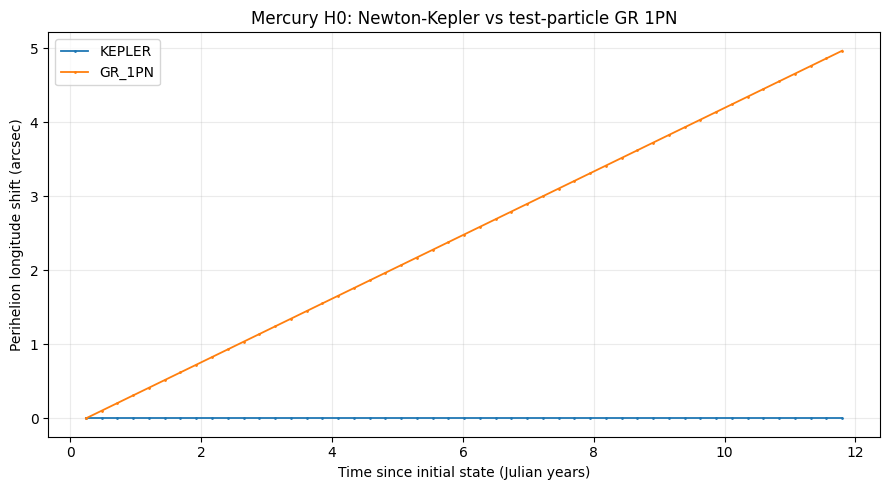

Saved: /content/GVH_CHH_MERCURY_1PN_CONTROL/Mercury_Kepler_vs_GR1PN_perihelion.png


In [6]:
fig,ax=plt.subplots(figsize=(9,5))
for label in ('KEPLER','GR_1PN'):
    v=runs[(1.0,label)]
    yrs=np.array(v['epochs_s'])/(YEAR_DAYS*86400)
    longitudes=(np.array(v['perihelion_angles_rad'])-v['perihelion_angles_rad'][0])*RAD_TO_ARCSEC
    ax.plot(yrs,longitudes,marker='.',ms=2,linewidth=1.3,label=label)
ax.set_xlabel('Time since initial state (Julian years)')
ax.set_ylabel('Perihelion longitude shift (arcsec)')
ax.set_title('Mercury H0: Newton-Kepler vs test-particle GR 1PN')
ax.grid(alpha=0.25)
ax.legend();fig.tight_layout()
plot_path=OUT/'Mercury_Kepler_vs_GR1PN_perihelion.png'
fig.savefig(plot_path,dpi=160)
plt.show();print('Saved:',plot_path)


## Niveau 4 — Verdict scientifique, traçabilité et archivage

**Interprétation attendue :**
- \(\dot\varpi_N\approx 0\) est un contrôle négatif.
- \(\dot\varpi_{GR1PN}\approx 43''/\mathrm{siècle}\) est un contrôle positif de la **physique connue**.
- La concordance analytique/numérique ne prouve ni un mécanisme CHH, ni une nouvelle loi GVH, ni un test instrumental indépendant.
- La prochaine étude confrontant JPL doit modéliser les perturbations des autres planètes, distinguer l'évolution du repère et séparer les contributions newtoniennes et relativistes ; ne pas interpréter directement un écart en modèle deux-corps comme une anomalie physique.


In [7]:
# Artéfacts reproductibles : CSV des périhélies, rapport JSON, résumé et ZIP.
rows=[]
for step in MAX_STEP_DAYS:
    for label in ('KEPLER','GR_1PN'):
        r=runs[(step,label)]
        for k,(t,ang) in enumerate(zip(r['epochs_s'],r['perihelion_angles_rad'])):
            rows.append(dict(model=label,max_step_days=step,event_index=k,
                             t_s=t,t_years=t/(YEAR_DAYS*86400),
                             longitude_rad=ang,shift_arcsec=(ang-r['perihelion_angles_rad'][0])*RAD_TO_ARCSEC))
csv_path=OUT/'Mercury_Perihelia.csv'
with csv_path.open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(rows[0]))
    writer.writeheader();writer.writerows(rows)
summary={
 'protocol':PROTOCOL,'state':'TWO_BODY_NUMERICAL_KNOWN_PHYSICS_ONLY',
 'CHH_INTRINSIC_DERIVATIVE':False,'AUX_DERIVATIVE_USED':True,'EOM_GVH_USED':False,
 'EMPIRICAL_RAW_ASTROMETRY_USED':False,'KNOWN_PHYSICS_1PN':True,
 'assumptions':'2D test particle, isolated static spherical Sun, harmonic-coordinate 1PN, no planet perturbations',
 'source_links':['https://ssd.jpl.nasa.gov/astro_par.html', 'https://ssd.jpl.nasa.gov/doc/Park.2021.AJ.DE440.pdf',
                 'https://www.damtp.cam.ac.uk/user/tong/gr/grhtml/S1.html',
                 'https://sites.science.oregonstate.edu/coursewikis/GGR/book/content/mercury'],
 'constants':{'solar_GM_km3_s2':MU_SUN,'c_km_s':C_KM_S,'au_km':AU_KM,'a_km':A_KM,
              'eccentricity':ECC,'duration_years':DURATION_YEARS,'rtol':REL_TOL,'atol':ABS_TOL,'max_steps_days':MAX_STEP_DAYS},
 'analytic_1PN_arcsec_century':float(predicted_arcsec_century),
 'numerical_1PN_minus_Kepler_arcsec_century_1day':float(nominal),
 'numerical_1PN_minus_Kepler_arcsec_century_05day':float(tight),
 'runs':[dict(model=m,**{k:v for k,v in runs[(s,m)].items() if k not in ('epochs_s','perihelion_angles_rad')}) for s in MAX_STEP_DAYS for m in ('KEPLER','GR_1PN')],
 'checks':checks,'scientific_verdict':verdict,
 'important_limit':'This is an analytic/numeric control, NOT independent astrometry, NOT new CHH physics.'}
report_path=OUT/'Mercury_1PN_H0_results.json'
report_path.write_text(json.dumps(summary,indent=2,ensure_ascii=False))
files_to_zip=[csv_path,plot_path,report_path]
hash_text=''.join(hashlib.sha256(fp.read_bytes()).hexdigest()+'  '+fp.name+'\n' for fp in files_to_zip)
(OUT/'SHA256SUMS.txt').write_text(hash_text)
zip_path=OUT.parent/'GVH_CHH_MERCURY_1PN_H0_RESULTS.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for fp in files_to_zip+[OUT/'SHA256SUMS.txt']:z.write(fp,fp.name)
assert zipfile.ZipFile(zip_path).testzip() is None
print('ZIP:',zip_path,'bytes:',zip_path.stat().st_size)
print('ZIP SHA256:',hashlib.sha256(zip_path.read_bytes()).hexdigest())
print('Verdict:',verdict)


ZIP: /content/GVH_CHH_MERCURY_1PN_H0_RESULTS.zip bytes: 62075
ZIP SHA256: 3acc2a2a877537d4fadf167633676350a9c013ff12350d398c89b1c67e32b22f
Verdict: PASS_NUMERICAL_MERCURY_1PN_CONTROL__KNOWN_PHYSICS_ONLY__CHH_ORIGINALITY_OPEN


In [ ]:
# Facultatif : copier les résultats dans Google Drive seulement après revue du verdict.
SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount('/content/drive')
    dst_dir=Path('/content/drive/MyDrive/Mercury_1PN')
    dst_dir.mkdir(parents=True,exist_ok=True)
    dst=dst_dir/zip_path.name
    shutil.copy2(zip_path,dst)
    assert hashlib.sha256(dst.read_bytes()).hexdigest()==hashlib.sha256(zip_path.read_bytes()).hexdigest()
    print('Saved to Drive and SHA256 verified:',dst)
else:
    print('SAVE_TO_DRIVE=False: archive remains in current Colab runtime. Set True and rerun this cell to save.')
